DATA PREPARATION COMPLETED
Dataset records: 299
Number of features: 13

TARGET DISTRIBUTION:
Customer Category (if applicable)
Small Business    68
Family            62
Regular           59
Senior Citizen    58
Student           52
Name: count, dtype: int64

MISSING VALUES:
Product Name or Type      0
Product Classification    0
Product Form              0
Quantity Sold             0
Promotion Type            0
Selling Price (PHP)       0
Total Sales (PHP)         0
Supplier/Source           0
Inventory Level           0
Payment Method            0
Sale Month                0
Sale Day                  0
Days Until Expiration     0
dtype: int64

FEATURE COLUMNS:
['Product Name or Type', 'Product Classification', 'Product Form', 'Quantity Sold', 'Promotion Type', 'Selling Price (PHP)', 'Total Sales (PHP)', 'Supplier/Source', 'Inventory Level', 'Payment Method', 'Sale Month', 'Sale Day', 'Days Until Expiration']
TRAINING RECORDS: 239
TESTING RECORDS: 60

TRAINING CATEGORY DISTRIBUTION:
Cu

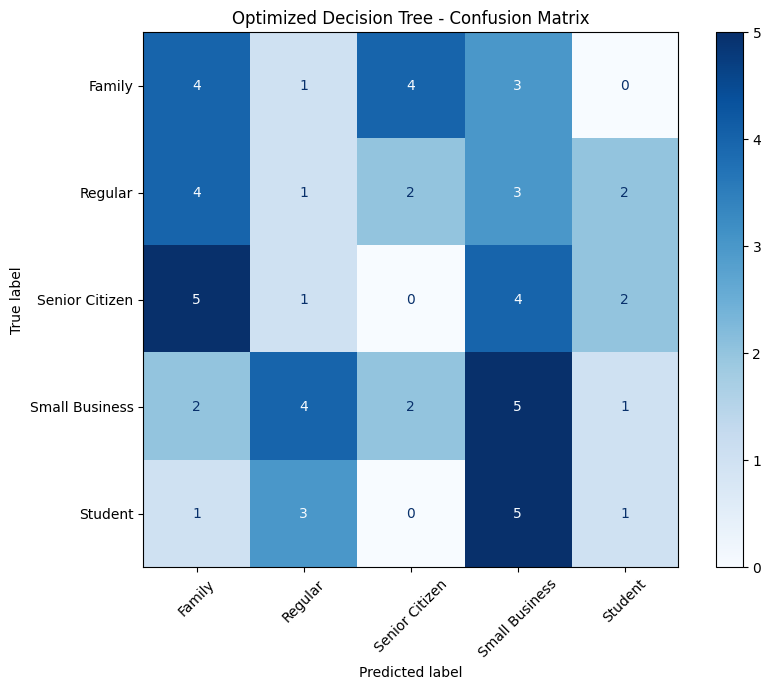

MODEL PERFORMANCE COMPARISON


,Model,Accuracy (%),Macro F1-score
0,Baseline Model,23.3333,0.0757
1,Default Decision Tree,21.6667,0.2045
2,Optimized Decision Tree,18.3333,0.1591


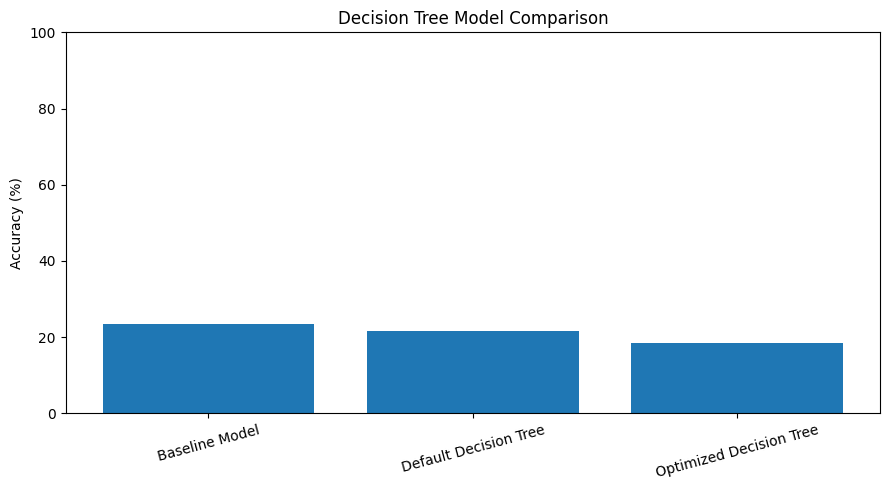


ORIGINAL MODEL ACCURACY: 23.33%
NEW OPTIMIZED MODEL ACCURACY: 18.33 %
TOP 15 FEATURE IMPORTANCE


,Feature,Importance
4,num__Sale Month,0.2123
0,num__Quantity Sold,0.1860
5,num__Sale Day,0.1760
2,num__Total Sales (PHP),0.1417
3,num__Inventory Level,0.1187
1,num__Selling Price (PHP),0.1059
45,cat__Product Form_sack,0.0595
7,cat__Product Name or Type_bath soap,0.0000
8,cat__Product Name or Type_biscuits,0.0000
9,cat__Product Name or Type_bottled water,0.0000


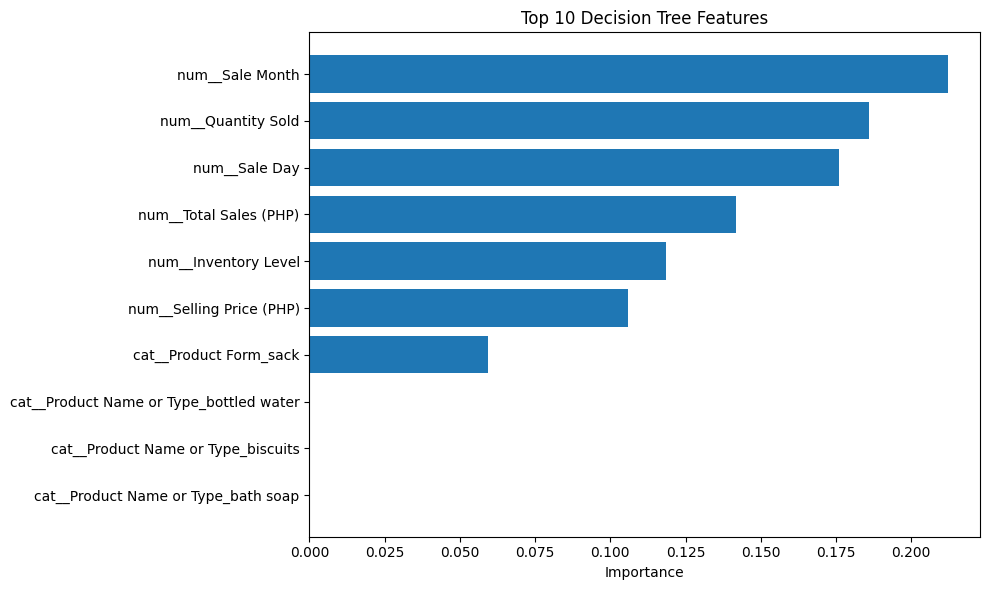

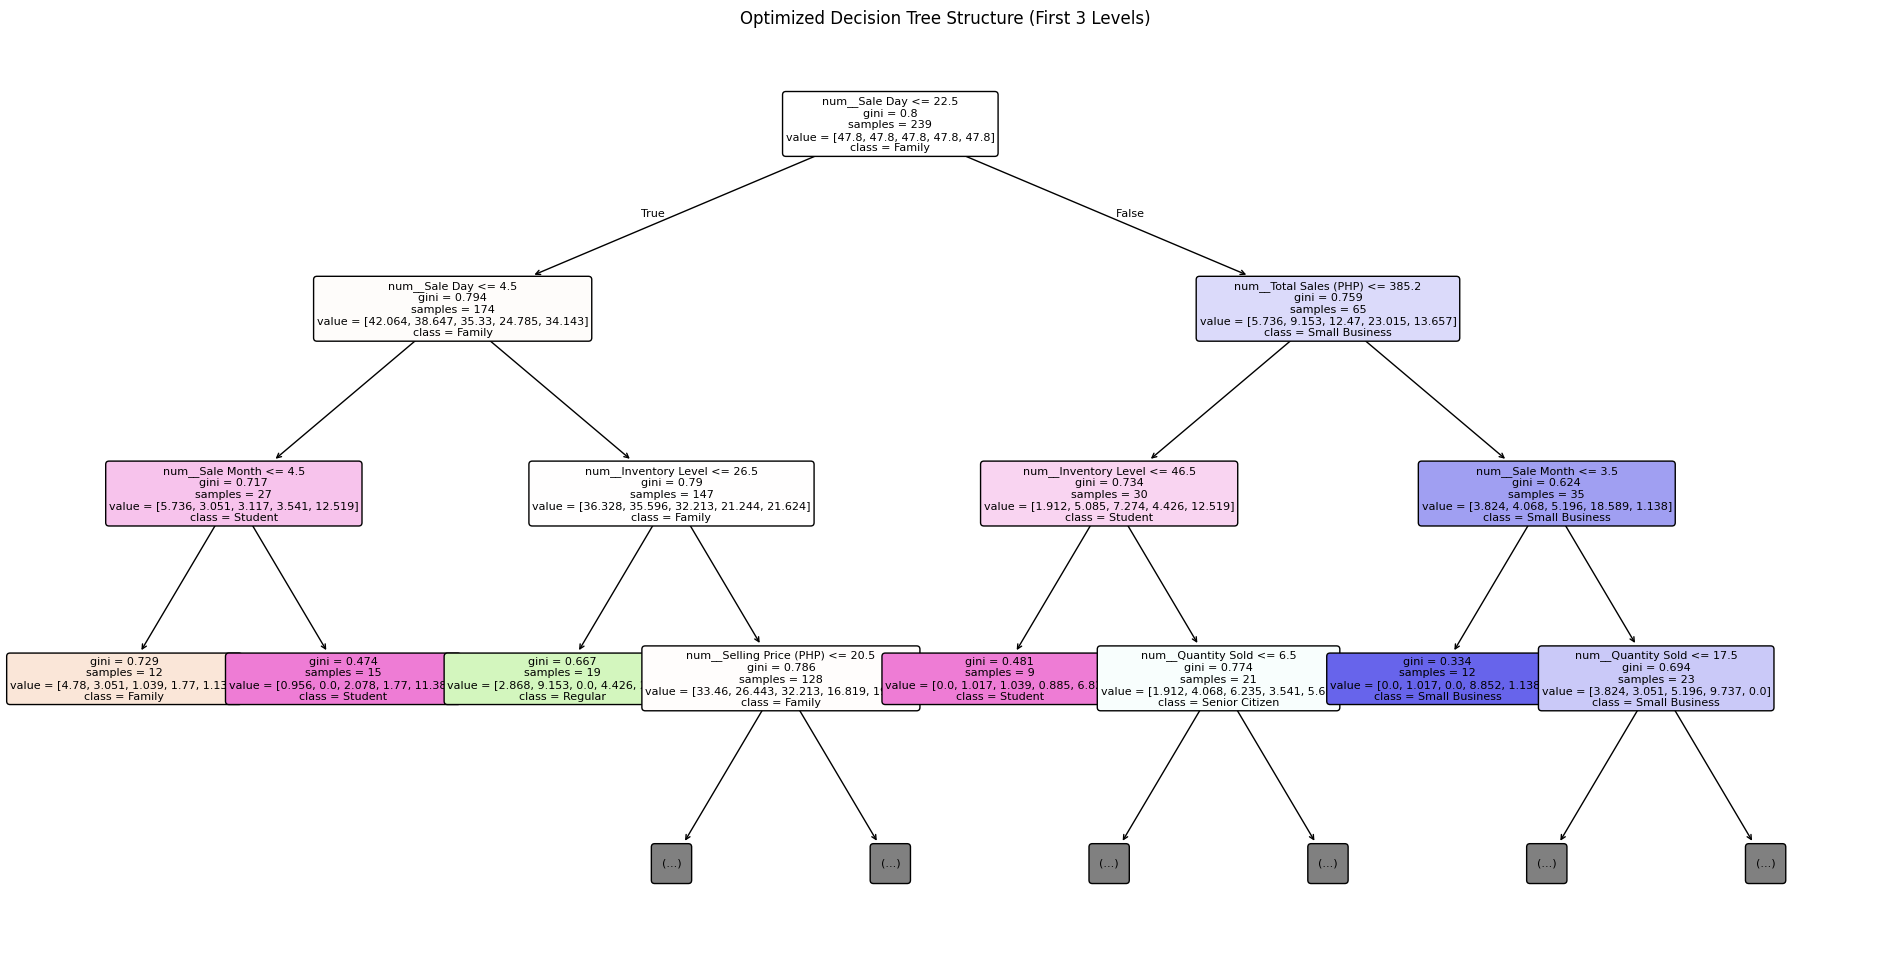

FINAL DECISION TREE OPTIMIZATION SUMMARY

DATASET INFORMATION
Total records: 299
Training records: 239
Testing records: 60
Target variable: Customer Category (if applicable)

MODEL ACCURACY
Baseline: 23.33%
Default Decision Tree: 21.67%
Optimized Decision Tree: 18.33%

BEST PARAMETERS
classifier__class_weight : balanced
classifier__criterion : gini
classifier__max_depth : 7
classifier__min_samples_leaf : 8
classifier__min_samples_split : 20

BEST CROSS-VALIDATION MACRO F1
0.2393

FINAL INTERPRETATION
Optimized model did not outperform the baseline.

PHASE A COMPLETED!


In [ ]:

# ==========================================
# PHASE A - STEP 1
# DATA CLEANING AND PREPROCESSING
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

from sklearn.inspection import permutation_importance

# Load dataset using verified path
df = pd.read_excel("/content/babae.xlsx")

# Target variable
target = "Customer Category (if applicable)"

# Remove duplicate product column
df = df.drop(
    columns=["Product Name or Type (Duplicate)"],
    errors="ignore"
)

# Remove records without target
df = df.dropna(subset=[target]).copy()

# Clean target labels
df[target] = df[target].astype(str).str.strip()

# Clean categorical text
categorical_text_columns = [
    "Product Name or Type",
    "Product Classification",
    "Product Form",
    "Promotion Type",
    "Supplier/Source",
    "Payment Method"
]

for col in categorical_text_columns:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype("string")
            .str.strip()
            .str.lower()
            .str.replace(r"\s+", " ", regex=True)
        )

# Convert currency columns
for col in ["Selling Price (PHP)", "Total Sales (PHP)"]:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col].astype(str).str.replace(
                r"[^\d.-]", "", regex=True
            ),
            errors="coerce"
        )

# Convert Excel date columns
date_columns = [
    "Date of Sale",
    "Expiration Date"
]

for col in date_columns:
    if col in df.columns:

        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = pd.to_datetime(
                df[col],
                unit="D",
                origin="1899-12-30",
                errors="coerce"
            )
        else:
            df[col] = pd.to_datetime(
                df[col],
                errors="coerce"
            )

# Create useful date features
df["Sale Month"] = df["Date of Sale"].dt.month
df["Sale Day"] = df["Date of Sale"].dt.day

df["Days Until Expiration"] = (
    df["Expiration Date"] - df["Date of Sale"]
).dt.days

# Remove raw dates and future information
df = df.drop(
    columns=[
        "Date of Sale",
        "Expiration Date",
        "Restock Date"
    ],
    errors="ignore"
)

# Separate features and target
X = df.drop(columns=[target])
y = df[target]

print("DATA PREPARATION COMPLETED")
print("Dataset records:", len(df))
print("Number of features:", X.shape[1])

print("\nTARGET DISTRIBUTION:")
print(y.value_counts())

print("\nMISSING VALUES:")
print(X.isnull().sum())

print("\nFEATURE COLUMNS:")
print(X.columns.tolist())


# ==========================================
# PHASE A - STEP 2
# TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAINING RECORDS:", len(X_train))
print("TESTING RECORDS:", len(X_test))

print("\nTRAINING CATEGORY DISTRIBUTION:")
print(y_train.value_counts())

print("\nTESTING CATEGORY DISTRIBUTION:")
print(y_test.value_counts())

# Identify feature types
categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCATEGORICAL FEATURES:")
print(categorical_features)

print("\nNUMERICAL FEATURES:")
print(numerical_features)

# Build preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Establish baseline model
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

print("\nBASELINE MODEL ACCURACY:")
print(f"{baseline_accuracy * 100:.2f}%")


# ==========================================
# PHASE A - STEP 3
# DEFAULT DECISION TREE
# ==========================================

default_tree = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

default_tree.fit(X_train, y_train)

default_pred = default_tree.predict(X_test)

default_accuracy = accuracy_score(
    y_test,
    default_pred
)

default_f1 = f1_score(
    y_test,
    default_pred,
    average="macro"
)

print("DEFAULT DECISION TREE RESULTS")
print("Accuracy:", round(default_accuracy * 100, 2), "%")
print("Macro F1-score:", round(default_f1, 4))


# ==========================================
# PHASE A - STEP 4
# DECISION TREE OPTIMIZATION
# ==========================================

decision_tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

# Parameter combinations
parameter_grid = {
    "classifier__criterion": [
        "gini",
        "entropy"
    ],

    "classifier__max_depth": [
        None,
        3,
        5,
        7,
        10
    ],

    "classifier__min_samples_split": [
        2,
        5,
        10,
        20
    ],

    "classifier__min_samples_leaf": [
        1,
        2,
        4,
        8
    ],

    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=decision_tree_pipeline,
    param_grid=parameter_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Train optimization using training data only
grid_search.fit(X_train, y_train)

# Best model
best_model = grid_search.best_estimator_

print("\nOPTIMIZATION COMPLETED")

print("\nBEST PARAMETERS:")
print(grid_search.best_params_)

print("\nBEST CROSS-VALIDATION MACRO F1:")
print(round(grid_search.best_score_, 4))


# ==========================================
# PHASE A - STEP 5
# OPTIMIZED MODEL EVALUATION
# ==========================================

optimized_pred = best_model.predict(X_test)

optimized_accuracy = accuracy_score(
    y_test,
    optimized_pred
)

optimized_f1 = f1_score(
    y_test,
    optimized_pred,
    average="macro"
)

print("OPTIMIZED DECISION TREE RESULTS")

print("\nAccuracy:")
print(f"{optimized_accuracy * 100:.2f}%")

print("\nMacro F1-score:")
print(round(optimized_f1, 4))

print("\nCLASSIFICATION REPORT:")

print(
    classification_report(
        y_test,
        optimized_pred,
        zero_division=0
    )
)


# ==========================================
# PHASE A - STEP 6
# CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_test,
    optimized_pred,
    labels=best_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    cmap="Blues",
    ax=ax,
    xticks_rotation=45
)

plt.title("Optimized Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()


# ==========================================
# PHASE A - STEP 7
# MODEL PERFORMANCE COMPARISON
# ==========================================

comparison = pd.DataFrame({
    "Model": [
        "Baseline Model",
        "Default Decision Tree",
        "Optimized Decision Tree"
    ],

    "Accuracy (%)": [
        baseline_accuracy * 100,
        default_accuracy * 100,
        optimized_accuracy * 100
    ],

    "Macro F1-score": [
        f1_score(y_test, baseline_pred, average="macro"),
        default_f1,
        optimized_f1
    ]
})

print("MODEL PERFORMANCE COMPARISON")

display(
    comparison.round(4)
)

# Visualize accuracy
plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy (%)"]
)

plt.ylabel("Accuracy (%)")
plt.title("Decision Tree Model Comparison")
plt.xticks(rotation=15)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

# Compare original historical accuracy
print("\nORIGINAL MODEL ACCURACY: 23.33%")
print(
    "NEW OPTIMIZED MODEL ACCURACY:",
    round(optimized_accuracy * 100, 2),
    "%"
)


# ==========================================
# PHASE A - STEP 8
# FEATURE IMPORTANCE
# ==========================================

trained_tree = best_model.named_steps["classifier"]

feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": trained_tree.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 FEATURE IMPORTANCE")

display(
    importance_df.head(15).round(4)
)

# Visualize top 10 features
top_features = importance_df.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.title("Top 10 Decision Tree Features")

plt.tight_layout()
plt.show()


# ==========================================
# PHASE A - STEP 9
# DECISION TREE VISUALIZATION
# ==========================================

plt.figure(figsize=(24, 12))

plot_tree(
    trained_tree,
    feature_names=feature_names,
    class_names=best_model.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Optimized Decision Tree Structure (First 3 Levels)")
plt.show()


# ==========================================
# PHASE A - STEP 10
# FINAL OPTIMIZATION SUMMARY
# ==========================================

print("=" * 55)
print("FINAL DECISION TREE OPTIMIZATION SUMMARY")
print("=" * 55)

print("\nDATASET INFORMATION")
print("Total records:", len(df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Target variable:", target)

print("\nMODEL ACCURACY")
print(f"Baseline: {baseline_accuracy * 100:.2f}%")
print(f"Default Decision Tree: {default_accuracy * 100:.2f}%")
print(f"Optimized Decision Tree: {optimized_accuracy * 100:.2f}%")

print("\nBEST PARAMETERS")
for parameter, value in grid_search.best_params_.items():
    print(parameter, ":", value)

print("\nBEST CROSS-VALIDATION MACRO F1")
print(round(grid_search.best_score_, 4))

print("\nFINAL INTERPRETATION")

if optimized_accuracy > baseline_accuracy:
    print("Optimized model outperformed the baseline on the test set.")
elif optimized_accuracy == baseline_accuracy:
    print("Optimized model matched the baseline accuracy.")
else:
    print("Optimized model did not outperform the baseline.")

print("\nPHASE A COMPLETED!")
